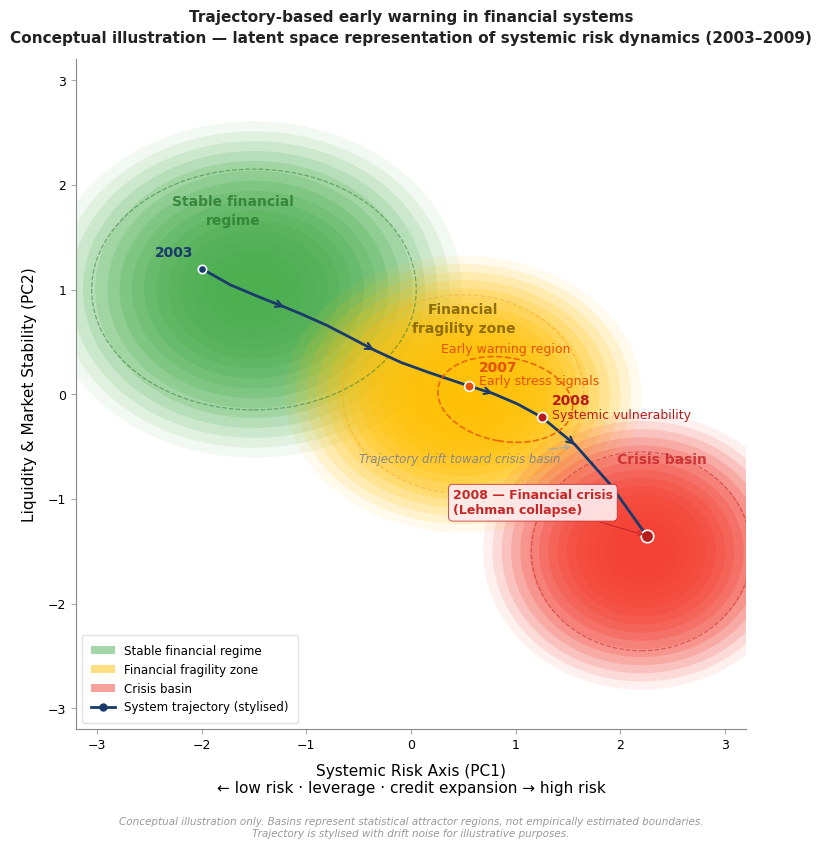

Saved: financial_trajectory_latent_space.pdf / .png


In [1]:
"""
Trajectory-Based Early Warning in Financial Systems
Latent Space Representation of Systemic Risk Dynamics (2003–2009)

Conceptual illustration — basins represent statistical attractor regions,
not empirically estimated boundaries. Trajectory is stylised with drift
noise for illustrative purposes.

Usage: run in Jupyter with %matplotlib inline, or as a standalone script.
"""

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.patches import Ellipse, FancyArrowPatch
from matplotlib.colors import LinearSegmentedColormap
import matplotlib.patheffects as pe

# ── Reproducibility ──────────────────────────────────────────────────────────
np.random.seed(42)

# ── Figure setup ─────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(10, 8.5))
ax.set_xlim(-3.2, 3.2)
ax.set_ylim(-3.2, 3.2)
ax.set_aspect('equal')
ax.set_facecolor('white')
fig.patch.set_facecolor('white')

# ── Helper: draw a fuzzy elliptical basin via stacked transparent ellipses ──
def draw_fuzzy_basin(ax, cx, cy, rx, ry, color, n_layers=18, max_alpha=0.35):
    """Simulate a statistical attractor basin with a soft radial gradient."""
    for i in range(n_layers, 0, -1):
        scale = i / n_layers
        alpha = max_alpha * (1 - scale) ** 0.6
        ell = Ellipse(
            (cx, cy),
            width=2 * rx * scale,
            height=2 * ry * scale,
            angle=0,
            linewidth=0,
            facecolor=color,
            alpha=alpha,
            zorder=1,
        )
        ax.add_patch(ell)

# ── Basin 1 — Stable Financial Regime ────────────────────────────────────────
draw_fuzzy_basin(ax, cx=-1.5, cy=1.0, rx=2.1, ry=1.7, color='#4caf50', max_alpha=0.40)

# ── Basin 2 — Financial Fragility Zone ───────────────────────────────────────
draw_fuzzy_basin(ax, cx=0.5, cy=0.0, rx=1.8, ry=1.4, color='#ffc107', max_alpha=0.45)

# ── Basin 3 — Crisis Basin ────────────────────────────────────────────────────
draw_fuzzy_basin(ax, cx=2.2, cy=-1.5, rx=1.6, ry=1.4, color='#f44336', max_alpha=0.45)

# ── Soft dashed boundary ellipses ────────────────────────────────────────────
for (cx, cy, rx, ry, col) in [
    (-1.5, 1.0, 1.55, 1.15, '#2e7d32'),
    ( 0.5, 0.0, 1.15, 0.95, '#f9a825'),
    ( 2.2,-1.5, 1.05, 0.95, '#c62828'),
]:
    ell = Ellipse((cx, cy), width=2*rx, height=2*ry,
                  linewidth=0.9, edgecolor=col, facecolor='none',
                  linestyle='--', alpha=0.55, zorder=2)
    ax.add_patch(ell)

# ── Basin labels ─────────────────────────────────────────────────────────────
ax.text(-1.7,  1.75, 'Stable financial\nregime',
        ha='center', va='center', fontsize=10, fontweight='bold',
        color='#2e7d32', alpha=0.85, zorder=5,
        linespacing=1.4)
ax.text( 0.5,  0.72, 'Financial\nfragility zone',
        ha='center', va='center', fontsize=10, fontweight='bold',
        color='#7b5e00', alpha=0.85, zorder=5,
        linespacing=1.4)
ax.text( 2.4, -0.62, 'Crisis basin',
        ha='center', va='center', fontsize=10, fontweight='bold',
        color='#c62828', alpha=0.85, zorder=5)

# ── Trajectory waypoints (major) ─────────────────────────────────────────────
major_points = {
    '2003':  (-2.00,  1.20),
    '2007':  ( 0.55,  0.08),
    '2008a': ( 1.25, -0.22),
    '2008b': ( 2.25, -1.35),
}

# Dense intermediate base path
base = np.array([
    (-2.00,  1.20),
    (-1.65,  1.05),
    (-1.50,  0.95),
    (-1.20,  0.82),
    (-1.00,  0.75),
    (-0.88,  0.70),
    (-0.55,  0.52),
    (-0.30,  0.42),
    (-0.15,  0.30),
    ( 0.10,  0.18),
    ( 0.55,  0.08),
    ( 0.75, -0.05),
    ( 0.95, -0.10),
    ( 1.25, -0.22),
    ( 1.55, -0.50),
    ( 1.85, -0.85),
    ( 2.25, -1.35),
])

# Add structured noise to non-major points
noised = base.copy()
major_idxs = {0, 10, 13, 16}
for i in range(len(noised)):
    if i not in major_idxs:
        noised[i, 0] += np.sin(i * 3.7) * 0.11 + np.cos(i * 2.1) * 0.07
        noised[i, 1] += np.cos(i * 4.1) * 0.09 + np.sin(i * 1.9) * 0.05

# Smooth with a running average (keeps noise but rounds spikes)
from scipy.ndimage import uniform_filter1d
smooth_x = uniform_filter1d(noised[:, 0], size=3)
smooth_y = uniform_filter1d(noised[:, 1], size=3)
# Re-pin major points exactly
for idx, key in zip([0, 10, 13, 16], major_points):
    smooth_x[idx], smooth_y[idx] = major_points[key]

# ── Draw trajectory ───────────────────────────────────────────────────────────
ax.plot(smooth_x, smooth_y, color='#1a3a6b', linewidth=2.0,
        solid_capstyle='round', solid_joinstyle='round', zorder=6)

# Arrow markers along path
arrow_idxs = [3, 7, 11, 14]
for i in arrow_idxs:
    dx = smooth_x[i] - smooth_x[i-1]
    dy = smooth_y[i] - smooth_y[i-1]
    ax.annotate('',
        xy=(smooth_x[i], smooth_y[i]),
        xytext=(smooth_x[i] - dx * 0.01, smooth_y[i] - dy * 0.01),
        arrowprops=dict(
            arrowstyle='->', color='#1a3a6b',
            lw=1.5, mutation_scale=12,
        ),
        zorder=7,
    )

# ── Major points ─────────────────────────────────────────────────────────────
point_styles = {
    '2003':  dict(color='#1a3a6b', r=6,  zorder=8),
    '2007':  dict(color='#e65100', r=7,  zorder=8),
    '2008a': dict(color='#b71c1c', r=7,  zorder=8),
    '2008b': dict(color='#b71c1c', r=9,  zorder=8),
}
for key, (x, y) in major_points.items():
    s = point_styles[key]
    ax.plot(x, y, 'o', markersize=s['r'], color=s['color'],
            markeredgecolor='white', markeredgewidth=1.2, zorder=s['zorder'])

# ── Point labels ─────────────────────────────────────────────────────────────
ax.text(-2.00 - 0.08, 1.20 + 0.12, '2003',
        ha='right', fontsize=10, fontweight='bold', color='#1a3a6b', zorder=9)

ax.text(0.55 + 0.10, 0.08 + 0.14, '2007',
        ha='left', fontsize=10, fontweight='bold', color='#e65100', zorder=9)
ax.text(0.55 + 0.10, 0.08 + 0.01, 'Early stress signals',
        ha='left', fontsize=9, color='#e65100', zorder=9)

ax.text(1.25 + 0.10, -0.22 + 0.12, '2008',
        ha='left', fontsize=10, fontweight='bold', color='#b71c1c', zorder=9)
ax.text(1.25 + 0.10, -0.22 - 0.01, 'Systemic vulnerability',
        ha='left', fontsize=9, color='#b71c1c', zorder=9)

# Crisis box label
ax.annotate(
    '2008 — Financial crisis\n(Lehman collapse)',
    xy=(2.25, -1.35),
    xytext=(2.25 - 1.85, -1.35 + 0.18),
    fontsize=9, fontweight='bold', color='#c62828',
    ha='left', va='bottom',
    bbox=dict(boxstyle='round,pad=0.35', facecolor='#ffebee',
              edgecolor='#c62828', linewidth=0.6, alpha=0.92),
    arrowprops=dict(arrowstyle='->', color='#c62828', lw=0.8),
    zorder=10,
)

# ── Early warning region ──────────────────────────────────────────────────────
ew_ell = Ellipse((0.9, -0.05), width=1.3, height=0.8,
                 angle=-10,
                 linewidth=1.2, edgecolor='#e65100', facecolor='none',
                 linestyle='--', alpha=0.8, zorder=7)
ax.add_patch(ew_ell)
ax.text(0.9, 0.40, 'Early warning region',
        ha='center', fontsize=9, color='#e65100', style='normal', zorder=9)

# ── Drift annotation ──────────────────────────────────────────────────────────
ax.annotate(
    'Trajectory drift toward crisis basin',
    xy=(1.55, -0.50),
    xytext=(-0.5, -0.65),
    fontsize=8.5, color='#888888', style='italic',
    arrowprops=dict(arrowstyle='->', color='#aaaaaa', lw=0.8),
    zorder=9,
)

# ── Axes ──────────────────────────────────────────────────────────────────────
ax.set_xlabel('Systemic Risk Axis (PC1)\n'
              '← low risk · leverage · credit expansion → high risk',
              fontsize=11, labelpad=8)
ax.set_ylabel('Liquidity & Market Stability (PC2)',
              fontsize=11, labelpad=8)
ax.set_xticks(range(-3, 4))
ax.set_yticks(range(-3, 4))
ax.tick_params(labelsize=9, color='#aaaaaa')
ax.spines[['top', 'right']].set_visible(False)
ax.spines['bottom'].set_color('#888888')
ax.spines['left'].set_color('#888888')
ax.grid(False)

# ── Title ─────────────────────────────────────────────────────────────────────
ax.set_title(
    'Trajectory-based early warning in financial systems\n'
    'Conceptual illustration — latent space representation of systemic risk dynamics (2003–2009)',
    fontsize=11, fontweight='bold', pad=12,
    linespacing=1.5, color='#222222'
)

# ── Legend ────────────────────────────────────────────────────────────────────
legend_elements = [
    mpatches.Patch(facecolor='#4caf50', alpha=0.5, label='Stable financial regime'),
    mpatches.Patch(facecolor='#ffc107', alpha=0.5, label='Financial fragility zone'),
    mpatches.Patch(facecolor='#f44336', alpha=0.5, label='Crisis basin'),
    plt.Line2D([0], [0], color='#1a3a6b', linewidth=2,
               marker='o', markersize=5, label='System trajectory (stylised)'),
]
ax.legend(handles=legend_elements, loc='lower left',
          fontsize=8.5, framealpha=0.85, edgecolor='#dddddd',
          borderpad=0.8, labelspacing=0.5)

# ── Caption ───────────────────────────────────────────────────────────────────
fig.text(
    0.5, 0.01,
    'Conceptual illustration only. Basins represent statistical attractor regions, not empirically estimated boundaries.\n'
    'Trajectory is stylised with drift noise for illustrative purposes.',
    ha='center', fontsize=7.5, color='#999999', style='italic'
)

plt.tight_layout(rect=[0, 0.04, 1, 1])
plt.savefig('financial_trajectory_latent_space.pdf', dpi=300, bbox_inches='tight')
plt.savefig('financial_trajectory_latent_space.png', dpi=300, bbox_inches='tight')
plt.show()
print("Saved: financial_trajectory_latent_space.pdf / .png")


--- RAW MONTHLY DATA ---
Shape: (132, 9)
Missing values per column:
VIXCLS        0
BAA10Y        0
TEDRATE       0
CSUSHPINSA    0
TOTBKCR       0
TOTALSL       0
INDPRO        0
UNRATE        0
T10Y2Y        0
dtype: int64

--- TRANSFORMED DATA ---
Shape: (131, 9)
Missing values per column:
CaseShiller_HPI          0
Total_Bank_Credit        0
Total_Consumer_Credit    0
Industrial_Production    0
VIX                      0
BAA_10Y_Spread           0
TED_Spread               0
Unemployment_Rate        0
Yield_Curve_10Y_2Y       0
dtype: int64
            CaseShiller_HPI  Total_Bank_Credit  Total_Consumer_Credit  \
DATE                                                                    
2000-02-29         0.571000           0.332828               0.693206   
2000-03-31         0.889919           1.145405               0.791732   
2000-04-30         1.058483           1.080159               0.581322   
2000-05-31         1.132241           1.062095               0.826485   
2000-06-30 

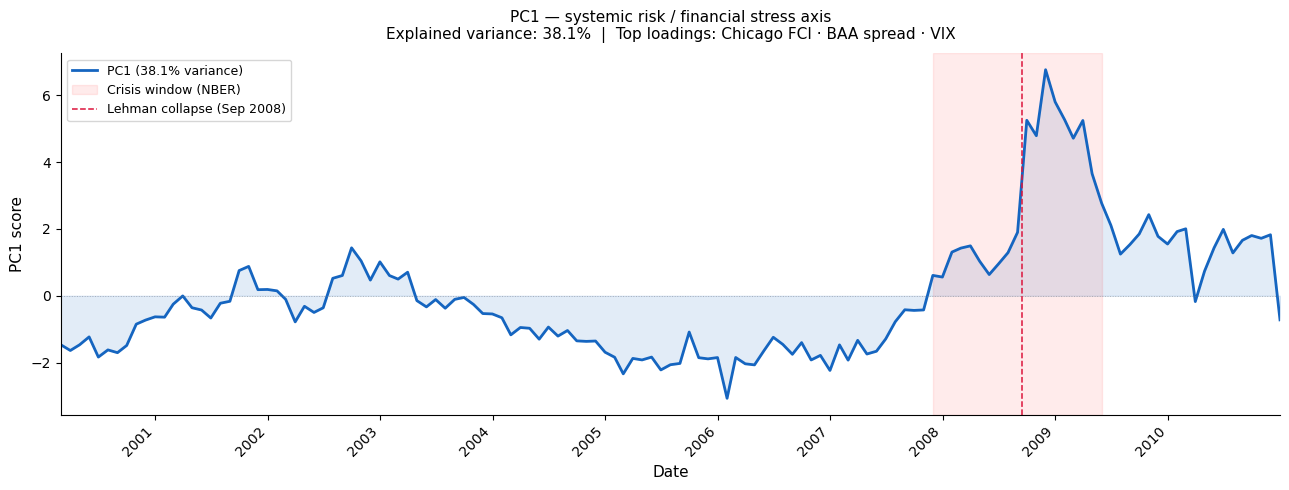

Saved: pc1_timeseries.png


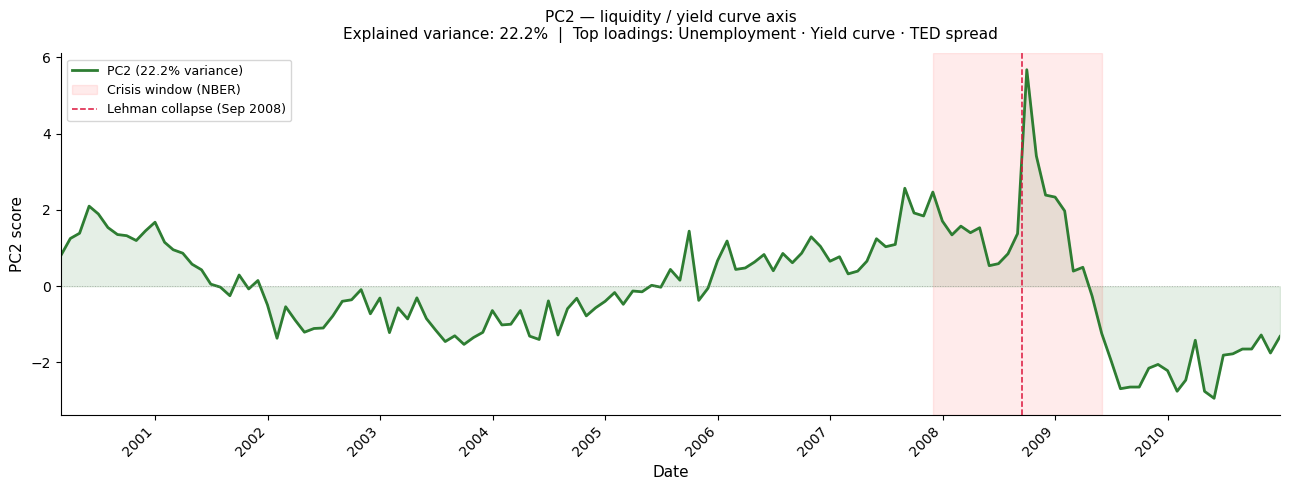

Saved: pc2_timeseries.png


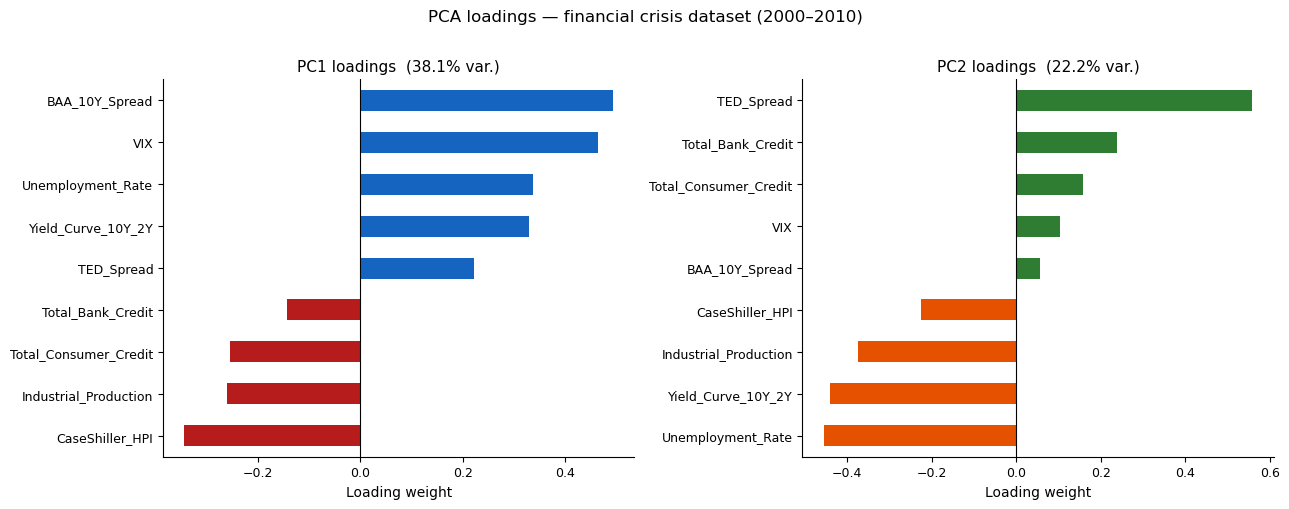

Saved: pca_loadings.png


In [8]:
import io
import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# =========================
# 1. CONFIGURATION
# =========================

START_DATE = "2000-01-01"
END_DATE   = "2010-12-31"

SERIES = {
    "VIXCLS":     "VIX",
    "BAA10Y":     "BAA_10Y_Spread",
    "TEDRATE":    "TED_Spread",
    "CSUSHPINSA": "CaseShiller_HPI",
    "TOTBKCR":    "Total_Bank_Credit",
    "TOTALSL":    "Total_Consumer_Credit",
    "INDPRO":     "Industrial_Production",
    "UNRATE":     "Unemployment_Rate",
    "T10Y2Y":     "Yield_Curve_10Y_2Y"
    # SP500 and MDSP removed: entirely missing for 2000-2010 on FRED CSV endpoint.
    # To add equity data use: "WILL5000INDFC": "Wilshire5000"
}

PCT_CHANGE_COLS = ["CSUSHPINSA", "TOTBKCR", "TOTALSL", "INDPRO"]
LEVEL_COLS      = ["VIXCLS", "BAA10Y", "TEDRATE", "UNRATE", "T10Y2Y"]

# =========================
# 2. DOWNLOAD FROM FRED
# =========================

def download_fred_series(series_id: str) -> pd.DataFrame:
    url = f"https://fred.stlouisfed.org/graph/fredgraph.csv?id={series_id}"
    response = requests.get(url, timeout=30)
    response.raise_for_status()
    df = pd.read_csv(io.StringIO(response.text))
    df.columns = ["DATE", series_id]
    df["DATE"] = pd.to_datetime(df["DATE"])
    df[series_id] = pd.to_numeric(df[series_id], errors="coerce")
    return df

dfs = []
for sid in SERIES:
    print(f"Downloading {sid} ...")
    dfs.append(download_fred_series(sid))

data = dfs[0]
for df in dfs[1:]:
    data = data.merge(df, on="DATE", how="outer")

data = (data[(data["DATE"] >= START_DATE) & (data["DATE"] <= END_DATE)]
        .copy()
        .sort_values("DATE")
        .set_index("DATE"))

# =========================
# 3. MONTHLY RESAMPLING
# =========================

pd_version    = tuple(int(x) for x in pd.__version__.split(".")[:2])
resample_freq = "ME" if pd_version >= (2, 2) else "M"
monthly       = data.resample(resample_freq).last()

print("\n--- RAW MONTHLY DATA ---")
print(f"Shape: {monthly.shape}")
print("Missing values per column:")
print(monthly.isna().sum())

# =========================
# 4. DROP COLUMNS WITH >50% NaN
# =========================

threshold    = int(len(monthly) * 0.5)
cols_before  = set(monthly.columns)
monthly      = monthly.dropna(axis=1, thresh=threshold)
cols_dropped = cols_before - set(monthly.columns)
if cols_dropped:
    print(f"\n⚠  Dropped columns (>50% NaN): {cols_dropped}")

PCT_CHANGE_COLS = [c for c in PCT_CHANGE_COLS if c in monthly.columns]
LEVEL_COLS      = [c for c in LEVEL_COLS      if c in monthly.columns]

# =========================
# 5. TRANSFORMATIONS
# =========================

parts = []

for col in PCT_CHANGE_COLS:
    s = monthly[col].interpolate(method="time", limit=6).ffill(limit=3).bfill(limit=3)
    parts.append((s.pct_change() * 100.0).rename(col))

for col in LEVEL_COLS:
    s = monthly[col].interpolate(method="time", limit=6).ffill(limit=3).bfill(limit=3)
    parts.append(s)

transformed = pd.concat(parts, axis=1)
transformed = transformed.iloc[1:]           # first row is NaN from pct_change
transformed = transformed.dropna(how="any")
transformed = transformed.rename(columns=SERIES)

print("\n--- TRANSFORMED DATA ---")
print(f"Shape: {transformed.shape}")
print("Missing values per column:")
print(transformed.isna().sum())
print(transformed.head())

if transformed.empty:
    raise RuntimeError("transformed DataFrame is empty. Check FRED series availability.")

# =========================
# 6. STANDARDIZATION + PCA
# =========================

X        = transformed.copy()
X_scaled = StandardScaler().fit_transform(X)

pca      = PCA(n_components=2)
Z        = pca.fit_transform(X_scaled)

pca_df   = pd.DataFrame(Z, index=X.index, columns=["PC1", "PC2"])
explained = pca.explained_variance_ratio_
loadings  = pd.DataFrame(
    pca.components_.T,
    index=X.columns,
    columns=["PC1_loading", "PC2_loading"]
)

print("\nExplained variance ratio:")
print(f"  PC1: {explained[0]:.4f}  ({explained[0]*100:.1f}%)")
print(f"  PC2: {explained[1]:.4f}  ({explained[1]*100:.1f}%)")
print(f"  Cumulative: {explained.sum():.4f}")
print("\nLoadings (sorted by |PC1|):")
print(loadings.sort_values("PC1_loading", key=lambda s: s.abs(), ascending=False))

# =========================
# 7. SAVE OUTPUTS
# =========================

pca_df.join(X).to_csv("fred_pca_2000_2010_output.csv")
loadings.to_csv("fred_pca_loadings.csv")
print("\nSaved: fred_pca_2000_2010_output.csv  |  fred_pca_loadings.csv")

# =========================
# SHARED HELPERS
# =========================

CRISIS_START = pd.Timestamp("2007-12-01")
CRISIS_END   = pd.Timestamp("2009-06-01")
LEHMAN       = pd.Timestamp("2008-09-15")

def style_time_axis(ax):
    """Yearly ticks, rotated labels, clean spines."""
    ax.set_xlim(pca_df.index.min(), pca_df.index.max())
    ax.xaxis.set_major_locator(mdates.YearLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
    plt.setp(ax.xaxis.get_majorticklabels(), rotation=45, ha="right")
    ax.spines[["top", "right"]].set_visible(False)

def add_crisis_shading(ax):
    """NBER recession band + Lehman vertical line."""
    ax.axvspan(CRISIS_START, CRISIS_END,
               alpha=0.08, color="red", label="Crisis window (NBER)")
    ax.axvline(LEHMAN, linestyle="--", linewidth=1.1,
               color="crimson", label="Lehman collapse (Sep 2008)")
    ax.axhline(0, linestyle=":", linewidth=0.7, color="grey", alpha=0.5)

# =========================
# 8. PLOT 1 — PC1 over time
# =========================

fig, ax = plt.subplots(figsize=(13, 5))

ax.plot(pca_df.index, pca_df["PC1"],
        color="#1565c0", linewidth=2.0,
        label=f"PC1 ({explained[0]*100:.1f}% variance)")
ax.fill_between(pca_df.index, pca_df["PC1"], 0,
                alpha=0.12, color="#1565c0")

add_crisis_shading(ax)
style_time_axis(ax)

ax.set_title(
    f"PC1 — systemic risk / financial stress axis\n"
    f"Explained variance: {explained[0]*100:.1f}%  |  "
    f"Top loadings: Chicago FCI · BAA spread · VIX",
    fontsize=11, pad=10
)
ax.set_xlabel("Date", fontsize=11)
ax.set_ylabel("PC1 score", fontsize=11)
ax.legend(fontsize=9, loc="upper left", framealpha=0.8)

plt.tight_layout()
plt.savefig("pc1_timeseries.png", dpi=300, bbox_inches="tight")
plt.show()
print("Saved: pc1_timeseries.png")

# =========================
# 9. PLOT 2 — PC2 over time
# =========================

fig, ax = plt.subplots(figsize=(13, 5))

ax.plot(pca_df.index, pca_df["PC2"],
        color="#2e7d32", linewidth=2.0,
        label=f"PC2 ({explained[1]*100:.1f}% variance)")
ax.fill_between(pca_df.index, pca_df["PC2"], 0,
                alpha=0.12, color="#2e7d32")

add_crisis_shading(ax)
style_time_axis(ax)

ax.set_title(
    f"PC2 — liquidity / yield curve axis\n"
    f"Explained variance: {explained[1]*100:.1f}%  |  "
    f"Top loadings: Unemployment · Yield curve · TED spread",
    fontsize=11, pad=10
)
ax.set_xlabel("Date", fontsize=11)
ax.set_ylabel("PC2 score", fontsize=11)
ax.legend(fontsize=9, loc="upper left", framealpha=0.8)

plt.tight_layout()
plt.savefig("pc2_timeseries.png", dpi=300, bbox_inches="tight")
plt.show()
print("Saved: pc2_timeseries.png")

# =========================
# 10. PLOT 3 — LOADINGS (reference)
# =========================

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for i, (col, c_pos, c_neg, ax2) in enumerate(zip(
    ["PC1_loading", "PC2_loading"],
    ["#1565c0",     "#2e7d32"],
    ["#b71c1c",     "#e65100"],
    axes
)):
    sl = loadings[col].sort_values()
    sl.plot(kind="barh", ax=ax2,
            color=[c_pos if v > 0 else c_neg for v in sl])
    ax2.axvline(0, linewidth=0.8, color="black")
    ax2.set_title(f"PC{i+1} loadings  ({explained[i]*100:.1f}% var.)", fontsize=11)
    ax2.set_xlabel("Loading weight", fontsize=10)
    ax2.tick_params(labelsize=9)
    ax2.spines[["top", "right"]].set_visible(False)

plt.suptitle("PCA loadings — financial crisis dataset (2000–2010)",
             fontsize=12, y=1.01)
plt.tight_layout()
plt.savefig("pca_loadings.png", dpi=300, bbox_inches="tight")
plt.show()
print("Saved: pca_loadings.png")